# 04 · RQ2: Does Iran news push Brent into the turbulent regime?

> ⚠️ **The outputs and "What this means" cells below are from the run of Nov 27, before M2/M3 were changed** (controls now act only on calm → turbulent). This notebook is rerun after notebook 05 freezes the settings, and the "What this means" cells are rewritten from that run.

**The question in one sentence.** When there is more news about Iran in a week, is the market more likely to switch from calm to turbulent the next week, even after taking into account general geopolitical risk (GPR), stock-market fear (VIX) and how volatile last week already was?

**How we answer it.** We take the two-regime model from notebook 03 and let the chance of switching regimes depend on last week's news and risk measures. Then we test whether adding Iran news makes the model fit significantly better.

**The models.** It is a "ladder": each model adds something to the one before.

| Model | What changes the chance of switching regimes |
|---|---|
| M1 | nothing (fixed probabilities) |
| M2 | last week's GPR, VIX and volatility ("the controls"). They only change the chance of going calm → turbulent; the chance of calming down again is one fixed number |
| M3 | M2 + last week's Iran news share. **The main model for RQ2** |
| M3tone | M2 + the Iran **conflict** news share and the Iran **cooperation** news share, instead of the total Iran share |

Every news and risk variable only acts on the calm → turbulent switch (decided Nov 27: when the controls also acted on turbulent → calm, the model overfitted that direction in short samples). All these variables are last week's values, z-scored with their 2005–2012 mean and standard deviation (see notebook 03, section 1).

**Which years**
- **Main: 2005–2025** (Jan 14, 2005 → Dec 26, 2025). All main results come from here.
- **Supplement: 2005 → Nov 6, 2026.** It includes the 2026 holdout, so it is only shown for completeness and decides nothing.

**What the notebook does**
1. Fit the four models on 2005–2025 and check each fit.
2. Show the coefficients: what moves the chance of switching?
3. Test whether each extra variable improves the fit (LR tests). **M3 vs M2 is the main RQ2 test.**
4. Repeat notebook 03's tests on 2005–2025 (for the report only).
5. The probability of the turbulent regime over time, plus two figures.
6. M3-tone: does the *kind* of Iran news (conflict vs cooperation) matter?
7. Supplement: the same models including 2026.
8. Two simpler volatility models (HAR-X, GARCH-X) as a cross-check.
9. Automatic checks.

**Files it writes:** tables in `results/tables/` (`rq2_coefficients`, `rq2_lr_tests`, `rq2_fit_summary`, `rq1_tests_2005_2025`, the same with `_2026`, `rq2_m3tone`, `harx_insample`, `harx_ftest`, `garchx_insample`), the regime probabilities in `results/fits/insample_filtered_2005_2026.csv` (notebook 07 reads it), and the figures `rq2_filtered_prob.png` and `rq2_transition_probs.png`.

## 0 · Setup

Loads the Python packages and our own `brent` code, fixes the random seed (so every run gives the same numbers), and sets one switch: `RUN_BOOT_2025` (`True` = also run the slow bootstrap of section 4 on 2005–2025; off by default).

In [1]:
# Reload src/brent/*.py automatically when we edit them.
%load_ext autoreload
%autoreload 2

import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

import brent
from brent import config as C        # every constant and frozen decision
from brent import paths              # file locations + size budget
from brent import plots              # figure style + save_fig (150 dpi PNG)
from brent import design as D        # design matrices (the only place where lags happen)
from brent import ms                 # Markov-switching specs, fitting, durations
from brent import insample as I      # ladder fits, LR/Wald tests, coefficient tables, GARCH-X LR
from brent import benchmarks as B    # HAR-X and GARCH-X
from brent import forecast as F      # filter_fixed: filtered P(H) with fixed parameters
from brent import weekly as W        # week_ending (event date -> its Friday week)

np.random.seed(C.SEED)               # statsmodels' searches get their own seeds inside ms.fit_model
plots.setup_style()                  # inline figures at 100 dpi
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)   # show the 'note' columns in full

# ── FLAGS ─────────────────────────────────────────────────────────────────────────────────────
RUN_BOOT_2025 = False      # parametric bootstrap of 1 vs 2 regimes on 2005–2025 (C.BOOT_REPS fits, ~20+ min).
                           # Optional here (spec §7.4 step 4): RQ1's bootstrap lives in notebook 03.
STOP_ON_BAD_FIT = True     # stop if M3 or M3tone (main sample) is degenerate or not converged, then ask the user
SEP_LIMIT = 50             # |transition coefficient| above this = near-separation: the estimate is unreliable

# ── DATA ──────────────────────────────────────────────────────────────────────────────────────
panel = pd.read_csv(paths.PROCESSED / "weekly_panel.csv", parse_dates=["date"])
EVENT_WEEKS = {e[0]: W.week_ending(pd.Timestamp(e[1])) for e in C.EVENTS}   # the nine Iran event weeks
print(f"panel: {len(panel):,} weeks, {panel['date'].min().date()} -> {panel['date'].max().date()}")
print(f"main sample ends {C.RQ2_END}; supplement ends {C.FREEZE_DATE} (includes the 2026 holdout)")

panel: 1,140 weeks, 2005-01-07 -> 2026-11-06
main sample ends 2025-12-26; supplement ends 2026-11-06 (includes the 2026 holdout)


### Two decisions this notebook relies on

- **φ = one shared value for both regimes (`PHI_SWITCHING = False`).** Decided in notebook 03: on 2005–2018 the carry-over of last week's return was the same in the calm and the turbulent regime (p = 0.85). It is set in `config.py`, and the next cell checks that `config.py` and `rq1_decision.json` agree.
- **M3 variant**: whether Iran news may only change the chance of going calm → turbulent (`constrained`, the current setting) or both directions (`iran_both_logits`). This is decided later, in notebook 05. Until then the notebook uses the value in `config.py` and prints **PROVISIONAL**.

So: **rerun this notebook once more after notebook 05**, when the M3 variant is final.

In [2]:
# ── φ: DECIDED IN NOTEBOOK 03 ─────────────────────────────────────────────────────────────────
# Notebook 03 tested on 2005-2018 whether φ (the carry-over of last week's return) differs between the calm and the
# turbulent regime: p = 0.85, so no. Decision: PHI_SWITCHING = False = ONE φ shared by both regimes, set in config.py.
# Here we only check that config.py and the saved decision file agree, so every model below uses the decided value.
dec_path = paths.FROZEN / "rq1_decision.json"
if not dec_path.exists():
    raise FileNotFoundError("results/frozen/rq1_decision.json is missing: run notebook 03 first.")
rq1_decision = json.loads(dec_path.read_text())
assert C.PHI_SWITCHING is not None, "PHI_SWITCHING is not set in config.py: it should be False (notebook 03)."
assert C.PHI_SWITCHING == rq1_decision["phi_switching"], \
    f"config.PHI_SWITCHING={C.PHI_SWITCHING} but rq1_decision.json says {rq1_decision['phi_switching']}"
PHI = C.PHI_SWITCHING        # False: every model in this notebook uses one φ for both regimes
PHI_PROVISIONAL = False      # the decision is final (used by the checks cell)
print(f"φ switching = {PHI}: one shared φ for both regimes (config.py and rq1_decision.json agree; "
      f"notebook 03 test p = {rq1_decision['p_value']:.3f})")

# ── M3 VARIANT: FROM NOTEBOOK 05's FREEZE ─────────────────────────────────────────────────────
# Whether Iran news may affect only calm -> turbulent ('constrained') or both directions. Decided in notebook 05;
# until that exists, the config value is used and flagged as PROVISIONAL.
freeze_path = paths.FROZEN / "spec_freeze.json"
if freeze_path.exists():
    spec_freeze = json.loads(freeze_path.read_text())
    assert C.M3_VARIANT == spec_freeze["M3_VARIANT"], \
        f"config.M3_VARIANT='{C.M3_VARIANT}' but spec_freeze.json says '{spec_freeze['M3_VARIANT']}'"
    VARIANT_PROVISIONAL = False
    print(f"M3 variant = '{C.M3_VARIANT}' (matches spec_freeze.json)")
else:
    VARIANT_PROVISIONAL = True
    print("=" * 96)
    print(f"PROVISIONAL: M3_VARIANT not frozen yet (notebook 05); using config value '{C.M3_VARIANT}'. "
          "Rerun this notebook after the freeze.")
    print("=" * 96)
VARIANT = C.M3_VARIANT     # fit_ladder reads C.M3_VARIANT itself; M3tone inherits the same variant

φ switching = False: one shared φ for both regimes (config.py and rq1_decision.json agree; notebook 03 test p = 0.846)
PROVISIONAL: M3_VARIANT not frozen yet (notebook 05); using config value 'constrained'. Rerun this notebook after the freeze.


### What this means
- **Data:** all 1,140 weeks are loaded. The main results use the weeks up to Dec 26, 2025; only the supplement (section 7) also uses 2026.
- **φ:** every model uses one shared φ for both regimes, as decided in notebook 03.
- **M3 variant:** still `constrained` (Iran news can only push calm → turbulent, not the other way) and marked PROVISIONAL until notebook 05 decides it. That is why one check at the end says PENDING.

### Small helper functions

They only format and collect results; all the estimation code lives in `src/brent/` and is tested there. Two display rules:
- a standard error that cannot be computed prints as **n/a**, with the reason (it is never hidden);
- a coefficient bigger than 50 (in absolute value) is flagged as **near-separation**: a variable almost perfectly predicts the switches, so the size of that number and its SE are not reliable.

In [3]:
def nobs(fit):
    """Number of estimation weeks of a Markov-switching fit."""
    return len(fit.model.endog)


def fmt(v, nd=3):
    """Number as text; NaN -> 'n/a'."""
    return f"{v:.{nd}f}" if np.isfinite(v) else "n/a"


def fit_status(fits):
    """One row per fit: LL, free parameters, sample, convergence and degeneracy flags, time."""
    rows = []
    for k, f in fits.items():
        dates = f.model.data.row_labels
        rows.append({"model": k, "loglike": round(f.loglike, 3), "k_free": len(f.params) - len(f.fixed),
                     "n_obs": nobs(f), "first": dates[0].date(), "last": dates[-1].date(),
                     "converged": f.converged, "degenerate": f.degenerate, "relabeled": f.relabeled,
                     "refit_from_scratch": f.refit_from_scratch, "n_warnings": f.n_warnings,
                     "seconds": round(f.seconds, 1)})
    return pd.DataFrame(rows).set_index("model")


def flag_bad_fits(fits, label, stop):
    """Print every degenerate / non-converged fit; with stop=True, stop if M3 or M3tone is affected."""
    bad = {k: f for k, f in fits.items() if f.degenerate or not f.converged}
    if not bad:
        print(f"{label}: every fit converged and none is degenerate.")
        return
    for k, f in bad.items():
        what = " and ".join(w for w, flag in (("DEGENERATE", f.degenerate), ("NOT CONVERGED", not f.converged)) if flag)
        print(f"!! {label}: {k} is {what} (LL {f.loglike:.3f}, {f.n_warnings} warnings)")
    key = [k for k in bad if k in ("M3", "M3tone")]
    if key and stop:
        raise RuntimeError(f"{label}: {key} affected. Stop and ask the user before reading any result "
                           "(set STOP_ON_BAD_FIT = False only to inspect).")


def add_notes(ct):
    """coef_table + a 'note' column: why an SE is missing, and near-separation flags."""
    notes = []
    for _, r in ct.iterrows():
        n = []
        if r["fixed"]:
            n.append("fixed at 0 by the constraint (Iran only moves calm->turbulent)")
        elif not np.isfinite(r["se"]):
            n.append("SE n/a: Hessian not invertible here (typical at quasi-separation)")
        if abs(r["coef"]) > SEP_LIMIT:
            n.append(f"NEAR-SEPARATION: |coef| > {SEP_LIMIT}, unreliable")
        notes.append("; ".join(n))
    return ct.assign(note=notes)


def show_coefs(ct):
    """Display a coefficient table with n/a instead of NaN."""
    out = ct.copy()
    for c, nd in (("coef", 3), ("se", 3), ("z", 2), ("p", 3)):
        out[c] = [fmt(v, nd) for v in ct[c]]
    display(out.drop(columns="fixed"))


def beta_row(ct, model, var):
    """The calm->turbulent (N->H) row of one variable in one model."""
    return ct[(ct["model"] == model) & (ct["logit"] == "N->H") & (ct["var"] == var)].iloc[0]


LR_PAIRS = [("M2_vs_M1", "M1", "M2"), ("M3_vs_M2", "M2", "M3"), ("M3tone_vs_M2", "M2", "M3tone")]
LR_COLS = ["test", "model_restricted", "model_full", "lr_raw", "stat", "df", "pvalue", "negative",
           "k_restricted", "k_full", "coef", "se", "note"]


def lr_table(fits, coefs):
    """LR tests (df computed by lr_test from the free parameters) + the z-test of Iran's β in M3."""
    rows = [{"test": t, "model_restricted": a, "model_full": b, **I.lr_test(fits[a], fits[b]),
             "note": "chi2(df) LR test"} for t, a, b in LR_PAIRS]
    b = beta_row(coefs, "M3", C.IRAN_VAR)
    rows.append({"test": f"beta_{C.IRAN_VAR}_z", "model_full": "M3", "stat": b["z"], "pvalue": b["p"],
                 "coef": b["coef"], "se": b["se"], "note": "z = beta/SE, two-sided normal p (deck sign, N->H)"})
    return pd.DataFrame(rows).reindex(columns=LR_COLS)


def summary_table(fits):
    """fit_summary (LL, k, AIC, BIC, durations at the 2005-2012 average regressors, regime moments)."""
    return pd.DataFrame({k: I.fit_summary(f, nobs(f)) for k, f in fits.items()}).T.rename_axis("model").reset_index()

## 1 · Fit the four models on 2005–2025

- The code fits M1, then M2 starting from M1's answer, then M3 starting from M2's answer ("nesting starts"). Because each bigger model starts where the smaller one ended, it can only end with an equal or better fit. M3tone starts from M2's answer.
- Each fit also tries 30 random starting points plus a few extra restarts, and keeps the best healthy one.
- After every fit the regimes are relabelled so that **H is always the regime with the bigger variance**.
- Every fit is checked: did it **converge**, and is it **degenerate** (one regime collapses: tiny variance, or it lasts under 2 weeks on average)? If M3 or M3tone fails a check, the notebook stops.

In [ ]:
# FIT THE LADDER ON 2005–2025 
t0 = time.perf_counter()
L = I.fit_ladder(panel, C.RQ2_END, PHI, n_restarts=C.N_RESTARTS)
# M3tone = M2 + (iran_conflict, iran_coop) instead of iran_gdelt; it starts from M2 with both betas at 0.
# Only M3tone here: the other tone variants (M3toneL, M3gold) belong to notebook 08.
T = I.fit_tone(panel, C.RQ2_END, PHI, L, n_restarts=C.N_RESTARTS, variants=("M3tone",))
FITS = {**L, **T}
print(f"fitted {list(FITS)} on 2005–2025 (φ switching = {PHI}, variant '{VARIANT}') "
      f"in {time.perf_counter() - t0:.0f} s\n")
display(fit_status(FITS))
flag_bad_fits(FITS, "2005–2025", stop=STOP_ON_BAD_FIT)

fitted ['M1', 'M2', 'M3', 'M3tone'] on 2005–2025 (φ switching = False, variant 'constrained') in 29 s



,loglike,k_free,n_obs,first,last,converged,degenerate,relabeled,refit_from_scratch,n_warnings,seconds
model,,,,,,,,,,,
M1,-3208.432,7,1094,2005-01-14,2025-12-26,True,False,False,False,0,0.8
M2,-3201.127,13,1094,2005-01-14,2025-12-26,True,False,False,False,0,9.2
M3,-3200.873,14,1094,2005-01-14,2025-12-26,True,False,False,False,0,7.7
M3tone,-3200.796,15,1094,2005-01-14,2025-12-26,True,False,False,False,0,11.7


2005–2025: every fit converged and none is degenerate.


### What this means
- **All four models were fitted cleanly** on 1,094 weeks: every fit converged, none is degenerate (no collapsed regime), and there were no warnings.
- **Fit (log-likelihood, higher = better):** M1 −3208.4 → M2 −3201.1 → M3 −3200.9 → M3tone −3200.8. Each bigger model fits a little better, as it must. The step from M1 to M2 is clear (+7.3); the step from M2 to M3, which adds Iran news, is tiny (+0.25). That is a first hint that Iran news adds little. Section 3 tests whether these steps are significant.
- **Good news compared with notebook 03:** the huge, unreliable coefficients ("near-separation") from the 2005–2018 rehearsal do not appear here. With 20 years of data and more turbulent spells, the model can estimate both switching directions properly.

## 2 · The coefficients: what moves the chance of switching?

**How to read the table**
- Each model has two rows of coefficients:
  - **N→H (calm → turbulent):** positive = more of this variable last week gives a **higher** chance of turning turbulent. **For `iran_gdelt` this is RQ2's β.**
  - **H→N (turbulent → calm):** only the constant is estimated (the chance of calming down is one fixed number). The control and Iran rows are fixed at exactly 0 and show no standard error.
- **Size:** every variable is z-scored, so a coefficient is the effect of that variable being **one standard deviation (of 2005–2012) higher** last week. exp(coefficient) tells how many times the odds of switching get multiplied: e.g. β = 0.2 → odds × 1.22.
- **SE** = how uncertain the coefficient is; **z** = coefficient / SE; **p < 0.05** = significant at the 5% level.
- Under `constrained`, Iran's coefficient in the H→N row is fixed at 0, so it shows 0 with no SE.
- (Technical note: statsmodels models the chance of *staying* calm and of *leaving* turbulence. We flip the sign of the first one so both rows read naturally, the same convention as our intro deck.)

In [ ]:
# ── COEFFICIENT TABLES 
COEF = {k: I.coef_table(FITS[k], k) for k in ("M2", "M3", "M3tone")}   # one Hessian per model
coef_main = add_notes(pd.concat(COEF.values(), ignore_index=True))
paths.save_table(coef_main, "rq2_coefficients")
show_coefs(coef_main)

b = beta_row(coef_main, "M3", C.IRAN_VAR)
print(f"\nRQ2's β ({C.IRAN_VAR}, calm->turbulent, deck sign) = {b['coef']:+.3f}   SE {fmt(b['se'])}   "
      f"z {fmt(b['z'], 2)}   p {fmt(b['p'])}")
print(f"odds ratio exp(β) = {np.exp(b['coef']):.2f}: one 2005–2012 SD more Iran news last week multiplies the "
      "odds of a calm->turbulent switch by this factor")
n_sep = (coef_main["coef"].abs() > SEP_LIMIT).sum()
print(f"near-separation flags (|coef| > {SEP_LIMIT}): {n_sep}")

,model,logit,var,coef,se,z,p,note
0,M2,N->H,const,-4.298,0.751,-5.72,0.000,
1,M2,N->H,gpr,0.617,0.285,2.16,0.031,
2,M2,N->H,vix,0.268,0.495,0.54,0.588,
3,M2,N->H,log_rv,0.648,0.604,1.07,0.284,
4,M2,H->N,const,-2.506,0.825,-3.04,0.002,
5,M2,H->N,gpr,0.273,0.270,1.01,0.312,
6,M2,H->N,vix,-1.044,0.660,-1.58,0.113,
7,M2,H->N,log_rv,0.618,0.437,1.42,0.157,
8,M3,N->H,const,-4.354,0.818,-5.32,0.000,
9,M3,N->H,gpr,0.697,0.280,2.49,0.013,



RQ2's β (iran_gdelt, calm->turbulent, deck sign) = +0.202   SE 0.270   z 0.75   p 0.455
odds ratio exp(β) = 1.22: one 2005–2012 SD more Iran news last week multiplies the odds of a calm->turbulent switch by this factor
near-separation flags (|coef| > 50): 0


### What this means
**Calm → turbulent (the direction RQ2 is about), model M3:**

| Variable (last week) | Coefficient | p-value | In words |
|---|---|---|---|
| GPR (global geopolitical risk) | +0.70 | **0.013** | **significant:** one SD more geopolitical risk roughly doubles the odds of turning turbulent (×2.0) |
| VIX (stock-market fear) | +0.35 | 0.51 | not significant |
| last week's volatility | +0.61 | 0.35 | not significant |
| **Iran news** | **+0.20** | **0.455** | **not significant:** odds ×1.22, but the uncertainty is large; the 95% range for the odds effect runs from ×0.72 to ×2.08, so "no effect" fits the data fine |

- In an average week the chance of turning turbulent is small: about 1.3% (from the constant −4.35).
- **Turbulent → calm:** no variable is significant. A turbulent spell ends with about a 7% chance per week, i.e. after roughly 15 weeks on average.
- **M3tone:** conflict news +0.27 (p = 0.60) and cooperation news −0.11 (p = 0.87): neither is significant.
- Compared with the 2005–2018 rehearsal, Iran's β now has the expected positive sign, but it is still far from significant.

**Bottom line:** general geopolitical risk predicts the switch into turbulence; Iran-specific news adds no significant extra effect on top of it.

## 3 · Does each extra variable improve the fit? (LR tests)

**LR test** = 2 × (fit of the bigger model − fit of the smaller model), compared with a χ² distribution whose degrees of freedom (df) = the number of extra coefficients. A small p-value means the extra variables improve the fit significantly.

| Test | Question | df |
|---|---|---|
| M2 vs M1 | do GPR, VIX and volatility matter? | 3 (3 variables, calm → turbulent only) |
| **M3 vs M2** | **does Iran news matter? (the main RQ2 test)** | 1 under `constrained` (2 under `iran_both_logits`) |
| M3tone vs M2 | do the conflict and cooperation shares matter? | 2 (or 4) |

The df are counted by the code from the fitted models, never typed in.

**Also the z-test of β on its own.** With df = 1, the LR test and the z-test ask the same question (is β = 0?) and give close, but not identical, answers. With df = 2 they can differ, because the LR then tests both Iran coefficients together.

**The fit summary table** shows for each model: LL (log-likelihood, higher = better fit), AIC and BIC (fit scores that punish extra parameters, lower = better), and how many weeks each regime lasts on average.

A negative LR would mean the optimizer failed; it is set to 0 and flagged, never hidden.

In [ ]:
# ── LR TESTS 
lr_main = lr_table(FITS, coef_main)
paths.save_table(lr_main, "rq2_lr_tests")
display(lr_main.drop(columns=["k_restricted", "k_full"]).round(4))

# df must match the variant (a check of lr_test's count, not a typed-in value)
# M2 vs M1: 3 controls, calm->turbulent only (CONTROLS_ONLY_NH = True) -> df 3; in both directions it would be 6
DF_CONTROLS = 3 if C.CONTROLS_ONLY_NH else 6
EXPECTED_DF = {"constrained": {"M2_vs_M1": DF_CONTROLS, "M3_vs_M2": 1, "M3tone_vs_M2": 2},
               "iran_both_logits": {"M2_vs_M1": DF_CONTROLS, "M3_vs_M2": 2, "M3tone_vs_M2": 4}}[VARIANT]
df_ok = all(int(lr_main.set_index("test").loc[t, "df"]) == d for t, d in EXPECTED_DF.items())
print(f"df computed by lr_test match the '{VARIANT}' variant: {df_ok}")

m3 = lr_main.set_index("test").loc["M3_vs_M2"]
print(f"M3 vs M2: LR = {m3['stat']:.3f} (df {int(m3['df'])}, p {m3['pvalue']:.3f});  z² of β = {fmt(b['z'] ** 2)}"
      + ("  -> df = 1, so these two should be close" if m3["df"] == 1 else "  -> df > 1: different hypotheses"))

,test,model_restricted,model_full,lr_raw,stat,df,pvalue,negative,coef,se,note
0,M2_vs_M1,M1,M2,14.6102,14.6102,6.0,0.0235,False,NaN,NaN,chi2(df) LR test
1,M3_vs_M2,M2,M3,0.5081,0.5081,1.0,0.4760,False,NaN,NaN,chi2(df) LR test
2,M3tone_vs_M2,M2,M3tone,0.6632,0.6632,2.0,0.7178,False,NaN,NaN,chi2(df) LR test
3,beta_iran_gdelt_z,NaN,M3,NaN,0.7475,NaN,0.4547,NaN,0.2017,0.2698,"z = beta/SE, two-sided normal p (deck sign, N->H)"


df computed by lr_test match the 'constrained' variant: True
M3 vs M2: LR = 0.508 (df 1, p 0.476);  z² of β = 0.559  -> df = 1, so these two should be close


In [7]:
# ── FIT SUMMARY ───────────────────────────────────────────────────────────────────────────────
# Durations are expected weeks in a regime, 1/(1 - P(stay)), with every regressor at its 2005–2012 average
# (z = 0). AIC = 2k - 2LL, BIC = k ln(n) - 2LL: lower is better; BIC penalises extra parameters harder.
sum_main = summary_table(FITS)
paths.save_table(sum_main, "rq2_fit_summary")
display(sum_main.set_index("model").round(3))

,loglike,k,aic,bic,dur_N,dur_H,sigma2_N,sigma2_H,mu_N,mu_H
model,,,,,,,,,,
M1,-3208.432,7.0,6430.865,6465.848,58.836,11.793,13.995,79.720,0.329,-1.419
M2,-3201.127,13.0,6428.254,6493.223,74.521,13.258,14.093,84.994,0.318,-1.502
M3,-3200.873,14.0,6429.746,6499.713,78.809,14.708,14.209,84.822,0.328,-1.574
M3tone,-3200.796,15.0,6431.591,6506.555,79.786,12.999,14.333,86.907,0.324,-1.627


### What this means: the main RQ2 result
- **M2 vs M1:** LR = 14.6, df = 6, p = 0.024. The risk measures together significantly improve the model: the chance of switching really does depend on last week's risk (mainly GPR, section 2).
- **M3 vs M2, the RQ2 test:** LR = 0.51, df = 1, **p = 0.48**. **Adding Iran news does not significantly improve the model.** The z-test of β gives the same answer (p = 0.45; z² = 0.56 is close to the LR of 0.51, as expected with df = 1).
- **M3tone vs M2:** p = 0.72. Splitting Iran news into conflict and cooperation does not help either.
- **Fit summary:** after the penalty for extra parameters, BIC prefers the simplest model (M1 6,466 < M2 6,493 < M3 6,500); AIC slightly prefers M2. The regimes look the same in every model: calm weeks average about +0.33% with a weekly sd of about 3.7%; turbulent weeks about −1.5% with a weekly sd of about 9%. Calm spells last 59–80 weeks, turbulent spells 12–15 weeks.

**Answer to RQ2 (in sample, 2005–2025): no.** Once general geopolitical risk, VIX and last week's volatility are taken into account, weeks with more Iran news are **not** followed by a significantly higher chance of the market turning turbulent.

## 4 · Notebook 03's tests again, now on 2005–2025

- The same tests as notebook 03, on the longer sample, because the report shows them too.
- **For the report only: φ stays frozen**, whatever these numbers say.
- As in notebook 03, M1 here lets φ differ between regimes, otherwise φ could not be tested.

**The rows of the table**
- `1v2_lr`: LR of two regimes vs one. Its textbook p-value is not valid (see notebook 03, section 3); the correct bootstrap p-value (`1v2_bootstrap`) only runs if `RUN_BOOT_2025 = True`.
- `bic_one`, `bic_two`: BIC with one and with two regimes; lower wins.
- `mu_equal`, `phi_equal`: tests whether μ, and φ, are the same in both regimes.
- `dur_N`, `dur_H`: how many weeks a stay in each regime lasts on average.
- `weeks_N`, `weeks_H`: number of weeks with P(H) ≤ 0.5 (calm) and > 0.5 (turbulent).

In [ ]:
# ── RQ1 TESTS ON A GIVEN SAMPLE 
def rq1_tests(end, boot=False):
    """RQ1's tests on 2005 -> end, M1 with φ switching on. Returns (table, M1 fit, equality tests)."""
    spec = ms.make_specs(True)["M1"]                      # φ switching ON, as in notebook 03
    design = D.build_design(panel, spec, end)
    fit = ms.fit_ms(design, spec, None, C.SEARCH_REPS_FIRST, 0, C.SEED)
    n = len(design.y)
    # one regime: AR(1) by OLS = the Gaussian MLE (statsmodels' llf is that log-likelihood); k = c, φ, σ²
    ll_one = sm.OLS(design.y.values, sm.add_constant(design.X["r_lag"].values)).fit().llf
    k_one, k_two = 3, len(fit.params)
    lr = max(2 * (fit.loglike - ll_one), 0.0)
    eq = I.equality_tests(design, spec)                   # refits M1 and the two restricted models
    xi = F.filter_fixed(fit.model, fit.params.values)     # filtered P(H), never smoothed
    dur = ms.expected_durations(fit.params.values, fit.model)
    if boot:
        bt = I.bootstrap_lr_1v2(design.y, design.X, n_reps=C.BOOT_REPS, seed=C.SEED,
                                search_reps=C.SEARCH_REPS_FIRST)
        paths.save_table(pd.DataFrame({"lr_boot": bt["lr_boot"]}), f"rq1_bootstrap_draws_{end[:4]}")
        boot_row = (bt["lr"], np.nan, bt["pvalue"], f"B={C.BOOT_REPS}, valid {bt['n_valid']}, "
                    f"degenerate {bt['n_degenerate']}, failed {bt['n_failed']}")
    else:
        boot_row = (np.nan, np.nan, np.nan, "not run (RUN_BOOT_2025 = False)")
    rows = [("1v2_lr", lr, k_two - k_one, np.nan, "non-standard: chi2 p not valid (use the bootstrap)"),
            ("1v2_bootstrap", *boot_row),
            ("bic_one", k_one * np.log(n) - 2 * ll_one, np.nan, np.nan, f"LL {ll_one:.3f}, k {k_one}, n {n}"),
            ("bic_two", k_two * np.log(n) - 2 * fit.loglike, np.nan, np.nan, f"LL {fit.loglike:.3f}, k {k_two}, n {n}")]
    for key in ("mu", "phi"):
        e = eq.loc[key]
        rows.append((f"{key}_equal", e["lr"], e["df"], e["p_lr"],
                     f"N {e['est_N']:.3f}, H {e['est_H']:.3f}; Wald {fmt(e['wald'])} p {fmt(e['p_wald'])}; "
                     f"lr_raw {e['lr_raw']:.3f}"))
    rows += [("dur_N", dur["N"], np.nan, np.nan, "expected weeks per visit"),
             ("dur_H", dur["H"], np.nan, np.nan, "expected weeks per visit"),
             ("weeks_N", float((xi <= 0.5).sum()), np.nan, np.nan, "filtered P(H) <= 0.5"),
             ("weeks_H", float((xi > 0.5).sum()), np.nan, np.nan, "filtered P(H) > 0.5")]
    tab = pd.DataFrame(rows, columns=["test", "stat", "df", "pvalue", "note"]).assign(sample_end=end)
    return tab, fit, eq


t0 = time.perf_counter()
rq1_main, M1_rq1, eq_main = rq1_tests(C.RQ2_END, boot=RUN_BOOT_2025)
paths.save_table(rq1_main, "rq1_tests_2005_2025")
print(f"RQ1 tests on 2005–2025 in {time.perf_counter() - t0:.0f} s "
      f"(M1 φ-switching fit: converged {M1_rq1.converged}, degenerate {M1_rq1.degenerate})")
display(rq1_main.set_index("test").round(4))

RQ1 tests on 2005–2025 in 1 s (M1 φ-switching fit: converged True, degenerate False)


,stat,df,pvalue,note,sample_end
test,,,,,
1v2_lr,231.6471,5.0,NaN,non-standard: chi2 p not valid (use the bootstrap),2025-12-26
1v2_bootstrap,NaN,NaN,NaN,not run (RUN_BOOT_2025 = False),2025-12-26
bic_one,6667.4123,NaN,NaN,"LL -3323.210, k 3, n 1094",2025-12-26
bic_two,6470.7532,NaN,NaN,"LL -3207.386, k 8, n 1094",2025-12-26
mu_equal,4.2660,1.0,0.0389,"N 0.330, H -1.213; Wald 4.173 p 0.041; lr_raw 4.266",2025-12-26
phi_equal,2.0921,1.0,0.1481,"N 0.018, H 0.149; Wald 2.037 p 0.154; lr_raw 2.092",2025-12-26
dur_N,58.9950,NaN,NaN,expected weeks per visit,2025-12-26
dur_H,11.7458,NaN,NaN,expected weeks per visit,2025-12-26
weeks_N,959.0000,NaN,NaN,filtered P(H) <= 0.5,2025-12-26


In [9]:
# ── φ STAYS FROZEN ────────────────────────────────────────────────────────────────────────────
p_phi = eq_main.loc["phi", "p_lr"]
would = bool(p_phi < 0.05)
print(f"2005–2025 φ test: LR p = {p_phi:.3f} -> on this sample the rule (p < 0.05) would say "
      f"phi_switching = {would}.")
print(f"Frozen value (from 2005–2018): phi_switching = {PHI}. "
      + ("Same answer." if would == PHI else "DIFFERENT answer: reported only, φ is NOT changed."))
# Nothing above may change φ: re-read the decision and compare.
assert PHI == bool(json.loads(dec_path.read_text())["phi_switching"])
assert C.PHI_SWITCHING is None or C.PHI_SWITCHING == PHI

2005–2025 φ test: LR p = 0.148 -> on this sample the rule (p < 0.05) would say phi_switching = False.
Frozen value (from 2005–2018): phi_switching = False. Same answer.


### What this means
- **Two regimes are still clearly better than one** on 2005–2025: LR = 232 (even bigger than the 106 of 2005–2018) and BIC 6,471 vs 6,667. The bootstrap is not rerun here; notebook 03 already showed this is far beyond chance.
- **Average returns still differ** between the regimes (p = 0.039): calm +0.33% per week, turbulent −1.21%.
- **φ is still the same in both regimes** (p = 0.15), so the rule gives the same answer as in notebook 03: one shared φ. Nothing changes.
- On the longer sample, a calm spell lasts about 59 weeks and a turbulent one about 12; 135 of the 1,094 weeks (12%) are turbulent.
- **So the RQ1 findings of notebook 03 also hold on the full 2005–2025 sample.**

## 5 · The probability of the turbulent regime over time (2005–2026), and two figures

- These are **filtered** probabilities: each week uses data up to that week only, i.e. what someone could have known in real time. Smoothed probabilities (which also use later weeks) are never used.
- The parameters estimated on 2005–2025 are kept **fixed**, and the model is simply run forward to Nov 6, 2026. So the 2026 part shows what the 2005–2025 model says about the holdout, without refitting anything. The result is saved to `insample_filtered_2005_2026.csv` (notebook 07 uses it for the event plots).
- **Figure 1:** P(turbulent) for M1, M2 and M3, with the nine Iran events and a dashed line at Jan 1, 2026.
- **Figure 2:** the chance of switching calm → turbulent each week, for M2 and M3 (2005–2025). Where the two lines differ, Iran news changed the model's view. The small table below it lists the 5 weeks where Iran news changed that chance the most.

In [ ]:
# ── FILTERED P(H), 2005–2026, WITH THE 2005–2025 PARAMETERS 
frames, FILT_DIFF = [], {}
for k in ("M1", "M2", "M3"):
    fit = L[k]
    d26 = D.build_design(panel, fit.spec, C.FREEZE_DATE)          # same spec, data to Nov 6, 2026
    m26 = ms.make_model(d26, fit.spec)
    assert list(m26.param_names) == list(fit.params.index)        # same parameters, same order
    xi = F.filter_fixed(m26, fit.params.values)                   # parameters held fixed, nothing refitted
    xi_main = F.filter_fixed(fit.model, fit.params.values)        # the main fit's own filter (to 2025)
    FILT_DIFF[k] = float((xi.loc[xi_main.index] - xi_main).abs().max())
    frames.append(pd.DataFrame({"date": xi.index, "model": k, "xi_H": xi.values}))
filt = pd.concat(frames, ignore_index=True)
paths.FITS.mkdir(parents=True, exist_ok=True)
filt.to_csv(paths.FITS / "insample_filtered_2005_2026.csv", index=False, date_format="%Y-%m-%d")
print(f"saved insample_filtered_2005_2026.csv: {len(filt):,} rows "
      f"({filt.groupby('model').size().to_dict()}), {filt['date'].min().date()} -> {filt['date'].max().date()}")
print("max |filter to 2026 - filter to 2025| on the shared weeks:", {k: f"{v:.1e}" for k, v in FILT_DIFF.items()})

# weeks classified turbulent (filtered P(H) > 0.5), main sample vs. the 2026 holdout
filt["holdout"] = filt["date"] >= pd.Timestamp(C.HOLDOUT[0])
display(filt.assign(turbulent=filt["xi_H"] > 0.5).pivot_table(index="model", columns="holdout",
        values="turbulent", aggfunc="sum").rename(columns={False: "weeks H 2005–2025", True: "weeks H 2026"}))

saved insample_filtered_2005_2026.csv: 3,417 rows ({'M1': 1139, 'M2': 1139, 'M3': 1139}), 2005-01-14 -> 2026-11-06
max |filter to 2026 - filter to 2025| on the shared weeks: {'M1': '0.0e+00', 'M2': '0.0e+00', 'M3': '0.0e+00'}


holdout,weeks H 2005–2025,weeks H 2026
model,,
M1,139,36
M2,125,25
M3,122,26


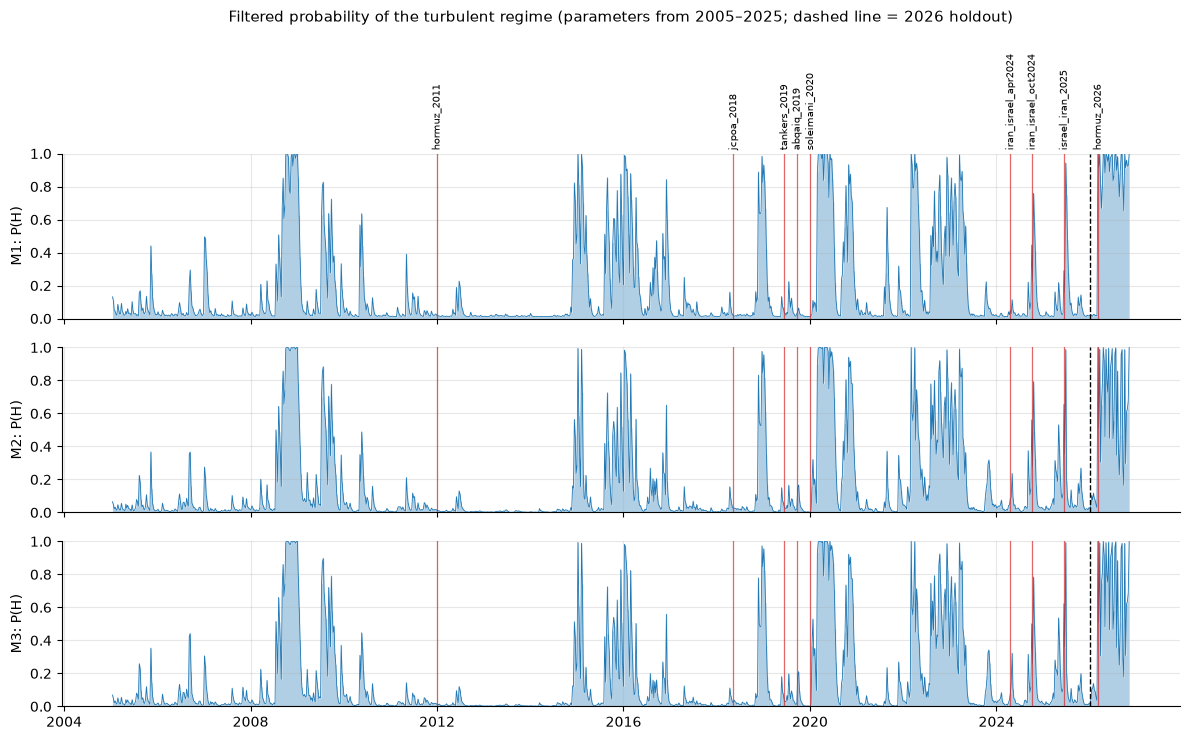

In [ ]:
# ── FIGURE: FILTERED P(H) FOR M1 / M2 / M3 
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
for ax, k in zip(axes, ("M1", "M2", "M3")):
    s = filt[filt["model"] == k]
    ax.fill_between(s["date"], 0, s["xi_H"], step="mid", color="tab:blue", alpha=0.35, lw=0)
    ax.plot(s["date"], s["xi_H"], color="tab:blue", lw=0.6)
    for w in EVENT_WEEKS.values():                               # the nine Iran event weeks
        ax.axvline(w, color="tab:red", lw=0.9, alpha=0.7)
    ax.axvline(pd.Timestamp("2026-01-01"), color="k", ls="--", lw=1)   # start of the 2026 holdout
    ax.set_ylim(0, 1)
    ax.set_ylabel(f"{k}: P(H)")
for name, w in EVENT_WEEKS.items():                              # event labels on the top panel
    axes[0].text(w, 1.02, name, rotation=90, fontsize=7, va="bottom", ha="center",
                 transform=axes[0].get_xaxis_transform())
axes[0].set_title("Filtered probability of the turbulent regime (parameters from 2005–2025; dashed line = 2026 holdout)",
                  pad=95)
fig.tight_layout()
plots.save_fig(fig, "rq2_filtered_prob")
plt.show()

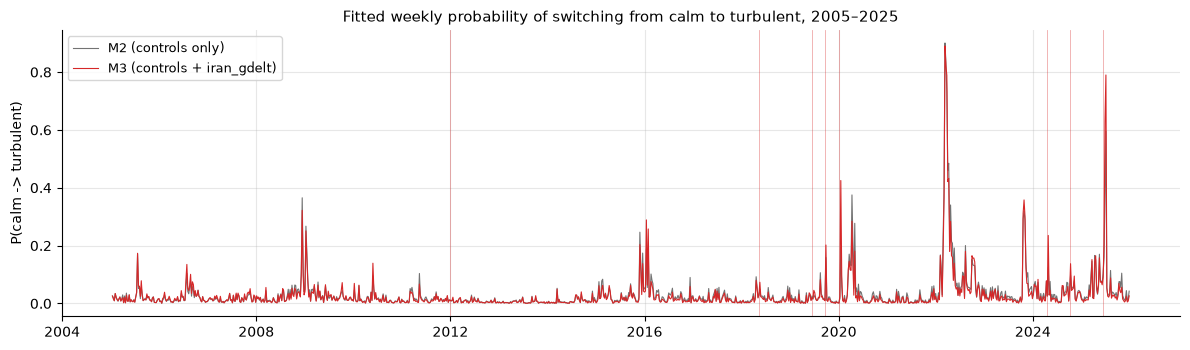

mean P(N->H): M2 0.0322, M3 0.0295; correlation 0.971
weeks where Iran news moves P(N->H) most (M3 - M2):


,M3 - M2
date,
2025-06-27,0.2383
2020-01-17,0.2295
2025-07-04,0.1948
2024-04-26,0.1102
2016-01-15,0.0997


In [12]:
# ── FIGURE: FITTED P(CALM -> TURBULENT) OVER TIME, M2 VS M3 (2005–2025) ───────────────────────
# statsmodels' transition matrix P[i, j, t] = P(regime i at t | regime j at t-1), so [1, 0, :] = P(N -> H).
PNH = {}
for k in ("M2", "M3"):
    fit = L[k]
    Z = D.build_design(panel, fit.spec, C.RQ2_END).Z              # the TVTP regressors the fit used
    P = np.asarray(fit.model.regime_transition_matrix(fit.params.values, exog_tvtp=Z.values))
    PNH[k] = pd.Series(P[1, 0, :], index=Z.index)

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(PNH["M2"].index, PNH["M2"], lw=0.8, color="0.45", label="M2 (controls only)")
ax.plot(PNH["M3"].index, PNH["M3"], lw=0.8, color="tab:red", label=f"M3 (controls + {C.IRAN_VAR})")
for w in EVENT_WEEKS.values():
    if w <= pd.Timestamp(C.RQ2_END):
        ax.axvline(w, color="tab:red", lw=0.6, alpha=0.4)
ax.set_ylabel("P(calm -> turbulent)")
ax.set_title("Fitted weekly probability of switching from calm to turbulent, 2005–2025")
ax.legend(loc="upper left")
fig.tight_layout()
plots.save_fig(fig, "rq2_transition_probs")
plt.show()

gap = PNH["M3"] - PNH["M2"]
print(f"mean P(N->H): M2 {PNH['M2'].mean():.4f}, M3 {PNH['M3'].mean():.4f}; correlation {PNH['M2'].corr(PNH['M3']):.3f}")
print("weeks where Iran news moves P(N->H) most (M3 - M2):")
display(gap.loc[gap.abs().nlargest(5).index].rename("M3 - M2").to_frame().round(4))

### What this means
**Figure 1 (probability of the turbulent regime):**
- M1, M2 and M3 agree almost completely on *when* the market was turbulent: the 2008–09 crash, the 2014–16 oil glut, the end of 2018, COVID in 2020, 2022–23, and most of 2026. Adding Iran news (M3) barely changes the picture.
- **Iran events:** at most of them the probability of turbulence stays low (Hormuz 2011, JCPOA 2018, the 2019 tanker and Abqaiq attacks, April 2024). There are short spikes around October 2024 and the June 2025 Israel–Iran war, which fade within weeks. The Soleimani strike (Jan 2020) came just before COVID, so the 2020 turbulence is mainly COVID.
- **2026:** the model is in the turbulent regime for most of the holdout (25–36 of 45 weeks), during the Hormuz crisis. That is the one Iran episode that lines up with a long turbulent spell, and the model's parameters never saw it.

**Figure 2 (weekly chance of switching calm → turbulent, M2 vs M3):**
- The two lines are nearly identical (correlation 0.97; average 3.2% vs 3.0% per week). The biggest spike, about 90% in early 2022 (Russia's invasion of Ukraine), comes from geopolitical risk in general, not from Iran.
- The weeks where Iran news raises the chance the most: Jun 27 and Jul 4, 2025 (Israel–Iran war: +24 and +19 percentage points), Jan 17, 2020 (Soleimani: +23 points) and Apr 26, 2024 (+11 points). So Iran news does matter in the few really big Iran weeks, but there are too few of them to make the effect significant over 20 years.
- Caveat: the two 2025 weeks partly use filled-in GDELT values from the June 2025 outage (notebook 02).

## 6 · M3-tone: does the *kind* of Iran news matter?

M3tone splits Iran news into two shares: **conflict** (threats, attacks) and **cooperation** (talks, deals). Both may only change the chance of going calm → turbulent.

**Three results:**
1. β_conflict and β_coop, each with its standard error.
2. **LR test M3tone vs M2**: does Iran news, split this way, matter at all?
3. **Wald test β_conflict = β_coop**: does the *kind* of news matter beyond the *amount*? If the two are equal, only how much Iran news there is counts, not whether it is about conflict or cooperation.

**Good to know**
- A positive β_coop is not a contradiction: good news can move oil too (the 2015 nuclear deal changed how much Iranian oil the market expected).
- M3tone and M3 are not nested (neither is a special case of the other), so their LL and BIC are only compared descriptively, without a test.

**First, a collinearity check.** The conflict and cooperation shares move very closely with the total Iran share (notebook 02: correlations 0.93 and 0.98). When two variables move almost together, the model cannot tell their separate effects apart: each β gets a big standard error. In that case the Wald test is the main result to read.

In [13]:
# ── COLLINEARITY OF THE TONE SHARES (R20) ─────────────────────────────────────────────────────
# Correlation of the weekly series on the main sample. The model uses them lagged and z-scored, which does
# not change correlations (z-scoring is linear; the one-week lag shifts all series together).
S = panel.set_index("date").loc[C.SAMPLE_START:C.RQ2_END, [*C.IRAN_TONE_VARS, C.IRAN_VAR]]
rho = S.corr()
a, c = C.IRAN_TONE_VARS
pairs = [(a, c), (a, C.IRAN_VAR), (c, C.IRAN_VAR)]
for u, v in pairs:
    print(f"corr({u}, {v}) = {rho.loc[u, v]:+.3f}")
RHO_TONE = float(rho.loc[a, c])
if abs(RHO_TONE) > 0.9:
    print(f"\n|ρ({a}, {c})| > 0.9: the two shares nearly move together, so the individual β's are imprecise "
          "and the Wald test (equal β's) is the main statistic.")
else:
    print(f"\n|ρ({a}, {c})| ≤ 0.9: the individual β's are identified separately (still read them with their SEs).")
if max(abs(rho.loc[a, C.IRAN_VAR]), abs(rho.loc[c, C.IRAN_VAR])) > 0.9:
    print(f"A tone share is > 0.9 correlated with {C.IRAN_VAR}: M3tone and M3 carry nearly the same information.")

corr(iran_conflict, iran_coop) = +0.809
corr(iran_conflict, iran_gdelt) = +0.918
corr(iran_coop, iran_gdelt) = +0.975

|ρ(iran_conflict, iran_coop)| ≤ 0.9: the individual β's are identified separately (still read them with their SEs).
A tone share is > 0.9 correlated with iran_gdelt: M3tone and M3 carry nearly the same information.


In [ ]:
# ── M3-TONE TABLE 
ct_tone = coef_main[coef_main["model"] == "M3tone"]
lr_tone = I.lr_test(L["M2"], T["M3tone"])                                # df computed (2 or 4)
wald = I.wald_equal(T["M3tone"], *C.IRAN_TONE_VARS)                      # chi2(1), deck sign
s3, st = I.fit_summary(L["M3"], nobs(L["M3"])), I.fit_summary(T["M3tone"], nobs(T["M3tone"]))

rows = []
for v in C.IRAN_TONE_VARS:
    r = beta_row(ct_tone, "M3tone", v)
    rows.append((f"beta_{v}", r["coef"], r["se"], r["z"], np.nan, r["p"],
                 "deck sign, N->H; z-test" + (f"; {r['note']}" if r["note"] else "")))
rows.append(("lr_M3tone_vs_M2", lr_tone["lr_raw"], np.nan, lr_tone["stat"], lr_tone["df"], lr_tone["pvalue"],
             "chi2(df) LR, df from free parameters" + ("; NEGATIVE raw LR clipped" if lr_tone["negative"] else "")))
wald_note = "chi2(1) Wald of beta_conflict = beta_coop; value = beta_conflict - beta_coop"
if not np.isfinite(wald["stat"]):
    wald_note += "; n/a: covariance not usable (Hessian not invertible, typical at quasi-separation)"
rows.append(("wald_conflict_eq_coop", wald["diff"], wald["se"], wald["stat"], wald["df"], wald["pvalue"], wald_note))
for key, nm in (("loglike", "loglike"), ("bic", "bic"), ("aic", "aic")):
    rows.append((f"{nm}_M3tone", st[key], np.nan, np.nan, np.nan, np.nan, "non-nested with M3: descriptive"))
    rows.append((f"{nm}_M3", s3[key], np.nan, np.nan, np.nan, np.nan, "non-nested with M3tone: descriptive"))
rows.append((f"corr_{a}_{c}", RHO_TONE, np.nan, np.nan, np.nan, np.nan, "weekly levels, 2005-2025"))
m3tone_tab = pd.DataFrame(rows, columns=["item", "value", "se", "stat", "df", "pvalue", "note"])
paths.save_table(m3tone_tab, "rq2_m3tone")
display(m3tone_tab.set_index("item").round(4))

print(f"\nWald β_conflict = β_coop: stat {fmt(wald['stat'])}, p {fmt(wald['pvalue'])}  "
      f"(β_conflict - β_coop = {wald['diff']:+.3f}, SE {fmt(wald['se'])})")
print(f"LR M3tone vs M2: {lr_tone['stat']:.3f}, df {lr_tone['df']}, p {lr_tone['pvalue']:.3f}")
print(f"BIC M3tone {st['bic']:.2f} vs M3 {s3['bic']:.2f} -> "
      f"{'M3tone' if st['bic'] < s3['bic'] else 'M3'} has the lower BIC (descriptive)")

,value,se,stat,df,pvalue,note
item,,,,,,
beta_iran_conflict,0.2728,0.5185,0.5262,NaN,0.5987,"deck sign, N->H; z-test"
beta_iran_coop,-0.1098,0.6700,-0.1639,NaN,0.8698,"deck sign, N->H; z-test"
lr_M3tone_vs_M2,0.6632,NaN,0.6632,2.0,0.7178,"chi2(df) LR, df from free parameters"
wald_conflict_eq_coop,0.3826,1.1545,0.1098,1.0,0.7403,chi2(1) Wald of beta_conflict = beta_coop; value = beta_conflict - beta_coop
loglike_M3tone,-3200.7955,NaN,NaN,NaN,NaN,non-nested with M3: descriptive
loglike_M3,-3200.8731,NaN,NaN,NaN,NaN,non-nested with M3tone: descriptive
bic_M3tone,6506.5550,NaN,NaN,NaN,NaN,non-nested with M3: descriptive
bic_M3,6499.7125,NaN,NaN,NaN,NaN,non-nested with M3tone: descriptive
aic_M3tone,6431.5911,NaN,NaN,NaN,NaN,non-nested with M3: descriptive



Wald β_conflict = β_coop: stat 0.110, p 0.740  (β_conflict - β_coop = +0.383, SE 1.154)
LR M3tone vs M2: 0.663, df 2, p 0.718
BIC M3tone 6506.56 vs M3 6499.71 -> M3 has the lower BIC (descriptive)


### What this means
- **Neither kind of Iran news matters:** conflict news β = +0.27 (p = 0.60), cooperation news β = −0.11 (p = 0.87).
- **Wald test (equal effects):** p = 0.74, so there is no evidence that conflict and cooperation news have different effects.
- **LR test against M2:** p = 0.72; and BIC prefers M3 (6,500 vs 6,507): splitting the news costs a parameter without improving the fit.
- **Why M3tone looks almost the same as M3:** conflict and cooperation shares correlate 0.81 with each other (low enough to separate them), but 0.92 and 0.975 with the total Iran share. They carry nearly the same information as the total, so they cannot tell us much more.
- **So:** in 2005–2025, neither the *amount* nor the *kind* (conflict vs cooperation) of Iran news predicts the switch into turbulence.

## 7 · Supplement: the same models on 2005 → Nov 2026

*Supplement: includes the 2026 holdout.* The same four models are refitted on data up to Nov 6, 2026, with the same tables (file names end in `_2026`). Shown for completeness only: **nothing in the project is chosen from these numbers**.

Careful when comparing: with the 2026 Iran crisis inside the sample, the model can settle on a quite different solution, so these numbers are not always directly comparable with the main ones.

In [15]:
# ── REFIT ON 2005–2026 (SUPPLEMENT) ───────────────────────────────────────────────────────────
t0 = time.perf_counter()
L26 = I.fit_ladder(panel, C.FREEZE_DATE, PHI, n_restarts=C.N_RESTARTS)
T26 = I.fit_tone(panel, C.FREEZE_DATE, PHI, L26, n_restarts=C.N_RESTARTS, variants=("M3tone",))
FITS26 = {**L26, **T26}
print(f"supplement fits (includes the 2026 holdout) in {time.perf_counter() - t0:.0f} s\n")
display(fit_status(FITS26))
flag_bad_fits(FITS26, "2005–2026 supplement", stop=False)   # flagged loudly; the checks cell fails on degeneracy

coef26 = add_notes(pd.concat([I.coef_table(FITS26[k], k) for k in ("M2", "M3", "M3tone")], ignore_index=True))
lr26 = lr_table(FITS26, coef26)
sum26 = summary_table(FITS26)
paths.save_table(coef26, "rq2_coefficients_2026")
paths.save_table(lr26, "rq2_lr_tests_2026")
paths.save_table(sum26, "rq2_fit_summary_2026")
show_coefs(coef26)
display(lr26.drop(columns=["k_restricted", "k_full"]).round(4))
display(sum26.set_index("model").round(3))

supplement fits (includes the 2026 holdout) in 29 s



,loglike,k_free,n_obs,first,last,converged,degenerate,relabeled,refit_from_scratch,n_warnings,seconds
model,,,,,,,,,,,
M1,-3379.007,7,1139,2005-01-14,2026-11-06,True,False,False,False,0,0.8
M2,-3373.483,13,1139,2005-01-14,2026-11-06,True,False,False,False,0,6.1
M3,-3372.296,14,1139,2005-01-14,2026-11-06,True,False,False,False,0,9.7
M3tone,-3372.790,15,1139,2005-01-14,2026-11-06,True,False,False,False,0,12.8


2005–2026 supplement: every fit converged and none is degenerate.


,model,logit,var,coef,se,z,p,note
0,M2,N->H,const,-4.376,0.657,-6.66,0.000,
1,M2,N->H,gpr,0.551,0.300,1.84,0.066,
2,M2,N->H,vix,0.661,0.499,1.33,0.185,
3,M2,N->H,log_rv,0.309,0.637,0.48,0.628,
4,M2,H->N,const,-2.185,0.662,-3.30,0.001,
5,M2,H->N,gpr,-0.162,0.282,-0.57,0.565,
6,M2,H->N,vix,-0.336,0.564,-0.59,0.552,
7,M2,H->N,log_rv,-0.025,0.485,-0.05,0.959,
8,M3,N->H,const,-6.676,1.410,-4.73,0.000,
9,M3,N->H,gpr,1.257,0.377,3.34,0.001,


,test,model_restricted,model_full,lr_raw,stat,df,pvalue,negative,coef,se,note
0,M2_vs_M1,M1,M2,11.0492,11.0492,6.0,0.0869,False,NaN,NaN,chi2(df) LR test
1,M3_vs_M2,M2,M3,2.3723,2.3723,1.0,0.1235,False,NaN,NaN,chi2(df) LR test
2,M3tone_vs_M2,M2,M3tone,1.3849,1.3849,2.0,0.5004,False,NaN,NaN,chi2(df) LR test
3,beta_iran_gdelt_z,NaN,M3,NaN,2.0181,NaN,0.0436,NaN,0.6896,0.3417,"z = beta/SE, two-sided normal p (deck sign, N->H)"


,loglike,k,aic,bic,dur_N,dur_H,sigma2_N,sigma2_H,mu_N,mu_H
model,,,,,,,,,,
M1,-3379.007,7.0,6772.014,6807.280,69.361,15.453,14.553,93.340,0.310,-1.076
M2,-3373.483,13.0,6772.965,6838.458,80.545,9.889,14.402,92.820,0.301,-1.008
M3,-3372.296,14.0,6772.593,6843.123,794.169,5.470,17.727,148.457,0.164,-1.020
M3tone,-3372.790,15.0,6775.580,6851.149,95.798,11.698,14.656,94.997,0.317,-1.145


*Supplement: includes the 2026 holdout.* Notebook 03's tests on 2005–2026, and Iran's β and the M3-tone Wald test placed next to the main-sample values.

In [16]:
# ── RQ1 TESTS ON 2005–2026 AND A SIDE-BY-SIDE OF THE KEY NUMBERS (SUPPLEMENT) ─────────────────
rq1_26, M1_rq1_26, eq_26 = rq1_tests(C.FREEZE_DATE, boot=False)   # never bootstrapped on the holdout
paths.save_table(rq1_26, "rq1_tests_2026")
display(rq1_26.set_index("test").round(4))

b26 = beta_row(coef26, "M3", C.IRAN_VAR)
wald26 = I.wald_equal(T26["M3tone"], *C.IRAN_TONE_VARS)
side = pd.DataFrame({
    "2005–2025 (main)": [b["coef"], b["se"], b["p"], lr_main.set_index("test").loc["M3_vs_M2", "pvalue"],
                         wald["pvalue"]],
    "2005–2026 (supplement)": [b26["coef"], b26["se"], b26["p"], lr26.set_index("test").loc["M3_vs_M2", "pvalue"],
                               wald26["pvalue"]]},
    index=[f"β_{C.IRAN_VAR}", "SE", "p (z-test)", "p (LR M3 vs M2)", "p (Wald conflict = coop)"])
display(side.round(4))

,stat,df,pvalue,note,sample_end
test,,,,,
1v2_lr,294.9136,5.0,NaN,non-standard: chi2 p not valid (use the bootstrap),2026-11-06
1v2_bootstrap,NaN,NaN,NaN,not run (RUN_BOOT_2025 = False),2026-11-06
bic_one,7071.3785,NaN,NaN,"LL -3525.132, k 3, n 1139",2026-11-06
bic_two,6811.6544,NaN,NaN,"LL -3377.676, k 8, n 1139",2026-11-06
mu_equal,2.5582,1.0,0.1097,"N 0.311, H -0.932; Wald 2.732 p 0.098; lr_raw 2.558",2026-11-06
phi_equal,2.6632,1.0,0.1027,"N 0.016, H 0.157; Wald 2.532 p 0.112; lr_raw 2.663",2026-11-06
dur_N,70.4077,NaN,NaN,expected weeks per visit,2026-11-06
dur_H,15.1822,NaN,NaN,expected weeks per visit,2026-11-06
weeks_N,983.0000,NaN,NaN,filtered P(H) <= 0.5,2026-11-06


,2005–2025 (main),2005–2026 (supplement)
β_iran_gdelt,0.2017,0.6896
SE,0.2698,0.3417
p (z-test),0.4547,0.0436
p (LR M3 vs M2),0.4760,0.1235
p (Wald conflict = coop),0.7403,0.8288


### What this means (supplement: includes the 2026 holdout)
- **With 2026 included, Iran's β rises to 0.69 with p = 0.044** in the z-test, which looks significant.
- **But three warnings:**
  1. The LR test of M3 vs M2, which is the main test, is still not significant (p = 0.12).
  2. M3 settles on a different solution here: its calm regime lasts 794 weeks and its turbulent variance jumps to 148 (vs about 85 in the main sample). The model reshapes the regimes around 2026, so these numbers are not comparable with the main ones.
  3. 2026 is the holdout: it was set aside to *test* the models, so it cannot be used for the main conclusion.
- **RQ1 on 2005–2026:** two regimes are still clearly better than one (LR 295); the difference in average returns is no longer significant (p = 0.11), and φ is still the same (p = 0.10).
- **So:** the 2026 Hormuz crisis is where Iran news and turbulence come together strongly, and adding it pushes β up. Read it as a hint that Iran news matters in extreme episodes. The forecast comparison (notebook 06) and the event study (notebook 07) check this properly.

## 8 · Two simpler volatility models as a cross-check: HAR-X and GARCH-X

Suggested by the professor (Nov 23). Their role (benchmark, replacement or appendix) is decided later from the results; here they are only fitted in sample. Years: Jun 7, 2013 (the first clean week of hourly data) → Dec 26, 2025. Volatility is measured with the hourly realized variance.

**HAR-X** predicts this week's volatility (RV) from last week's RV, the average RV of the last 4 weeks and of the last 13 weeks, plus news variables.
- `HAR_h`: no news; `HARX_C`: + GPR and VIX; `HARX_CI`: + the Iran share.
- **Standard errors are Newey-West (HAC, 4 lags):** the errors are correlated from week to week and change in size over time, so ordinary standard errors would be too small.
- **F-tests:** does adding the variables improve the fit? They use ordinary standard errors, so read their p-values as a rough guide. For Iran, the HAC t-test of its coefficient is the more reliable version of the same question; both are printed.

**GARCH-X** is the classic volatility model: this week's variance = a constant + the effect of last week's surprise + last week's variance + γ × news variables.
- `GARCH_t`: no news; `GARCHX_C`: + last week's hourly RV, GPR and VIX (3 γ's); `GARCHX_CI`: + the Iran share (1 more γ).
- Each **γ must be ≥ 0**, so the variance stays positive. If a γ is truly 0, it sits right at that edge, and the LR test no longer follows the usual χ². The correct version is the **chi-bar-squared** test; for one extra γ its p-value is simply half the usual χ² p-value.
- When an estimated γ is exactly 0, its standard error cannot be computed, so it prints as **n/a**.
- `garchx_insample.csv` is in "long" format: its `value` column mixes different things (LL, γ, LR, p-values), so always read it together with the `term` column.

In [17]:
# ── HAR-X: COEFFICIENTS (HAC SEs) AND NESTED F-TESTS ──────────────────────────────────────────
HAR_X = {"HAR_h": (), "HARX_C": tuple(C.X_CONTROLS), "HARX_CI": tuple(C.X_CONTROLS) + (C.IRAN_VAR,)}
if "HAR_h" not in C.BENCHMARKS_MAIN:          # no-intraday fallback: HAR_h does not exist
    HAR_X.pop("HAR_h")
    print("HAR_h is not in C.BENCHMARKS_MAIN (no-intraday fallback): skipped")

har_tabs, har_ols = [], {}
for name, xv in HAR_X.items():
    t = B.harx_insample(panel, C.RQ2_END, C.X_RV_COL, xv, C.X_SAMPLE_START, hac_lags=4)   # Newey-West, 4 lags
    har_tabs.append(t.rename_axis("term").reset_index().assign(model=name))
    har_ols[name] = B.harx_ols(panel, C.RQ2_END, C.X_RV_COL, xv, C.X_SAMPLE_START)        # plain OLS for F-tests
harx_tab = pd.concat(har_tabs, ignore_index=True)[["model", "term", "coef", "se", "t", "p"]]
paths.save_table(harx_tab, "harx_insample")
assert len({int(r.nobs) for r in har_ols.values()}) == 1, "HAR models must share one sample for the F-tests"

wide = harx_tab.pivot(index="term", columns="model", values="coef")
print("coefficients (rows adj_r2 and n are fit statistics):")
display(wide.reindex(index=harx_tab["term"].unique(), columns=list(HAR_X)).round(4))   # keep the model's term order
print("HAC t-statistics:")
display(harx_tab.pivot(index="term", columns="model", values="t")
        .reindex(index=harx_tab["term"].unique(), columns=list(HAR_X)).dropna(how="all").round(2))

f_rows = []
for test, full, restr in (("HARX_CI_vs_HARX_C", "HARX_CI", "HARX_C"), ("HARX_C_vs_HAR_h", "HARX_C", "HAR_h")):
    if full in har_ols and restr in har_ols:
        Fv, pv, dfn = har_ols[full].compare_f_test(har_ols[restr])
        f_rows.append({"test": test, "F": Fv, "df_num": dfn, "df_resid": har_ols[full].df_resid,
                       "n": har_ols[full].nobs, "pvalue": pv})
harx_f = pd.DataFrame(f_rows, columns=["test", "F", "df_num", "df_resid", "n", "pvalue"])
paths.save_table(harx_f, "harx_ftest")
display(harx_f.round(4))

ci = harx_tab[(harx_tab["model"] == "HARX_CI") & (harx_tab["term"] == f"c_{C.IRAN_VAR}")].iloc[0]
print(f"Iran coefficient in HARX_CI: {ci['coef']:+.4f}, HAC SE {ci['se']:.4f}, t {ci['t']:.2f}, p {ci['p']:.3f} "
      "(robust counterpart of the HARX_CI vs HARX_C F-test)")

coefficients (rows adj_r2 and n are fit statistics):


model,HAR_h,HARX_C,HARX_CI
term,,,
b0,8.4816,20.0775,23.4457
b_rv1,0.2183,0.1744,0.1699
b_rv4,0.5222,0.4797,0.4760
b_rv13,-0.0555,-0.1506,-0.1391
adj_r2,0.3200,0.3523,0.3535
n,643.0000,643.0000,643.0000
c_gpr,NaN,-0.4106,-0.4712
c_vix,NaN,17.6301,18.1235
c_iran_gdelt,NaN,NaN,2.5332


HAC t-statistics:


model,HAR_h,HARX_C,HARX_CI
term,,,
b0,3.28,2.74,2.23
b_rv1,1.71,1.47,1.43
b_rv4,2.66,2.66,2.64
b_rv13,-0.65,-1.46,-1.47
c_gpr,NaN,-0.33,-0.36
c_vix,NaN,2.12,2.09
c_iran_gdelt,NaN,NaN,0.96


,test,F,df_num,df_resid,n,pvalue
0,HARX_CI_vs_HARX_C,2.1572,1.0,636.0,643.0,0.1424
1,HARX_C_vs_HAR_h,16.9626,2.0,637.0,643.0,0.0000


Iran coefficient in HARX_CI: +2.5332, HAC SE 2.6349, t 0.96, p 0.336 (robust counterpart of the HARX_CI vs HARX_C F-test)


In [ ]:
# ── GARCH-X: LR TESTS WITH CHI-BAR-SQUARED P-VALUES 
# garchx_lr fits the small and the big model on the same weeks; the big one starts from the small one's
# parameters with the new γ's at 0, so LL(big) >= LL(small).
t0 = time.perf_counter()
g_c = I.garchx_lr(panel, C.RQ2_END, None, tuple(C.X_CONTROLS))                         # GARCH_t -> GARCHX_C (k=3)
g_ci = I.garchx_lr(panel, C.RQ2_END, tuple(C.X_CONTROLS), tuple(C.X_CONTROLS) + (C.IRAN_VAR,))  # -> GARCHX_CI (k=1)
print(f"GARCH-X fits in {time.perf_counter() - t0:.0f} s")


def gamma_note(g, se):
    """Why a γ has no SE."""
    if np.isfinite(se):
        return "Hessian SE (unreliable near the gamma >= 0 bound)"
    return "SE n/a: gamma at the gamma >= 0 bound" if g <= 1e-6 else "SE n/a: Hessian singular"


g_rows = [("GARCH_t (SLSQP fit on the X sample)", "loglike", g_c["ll_small"], np.nan, "")]
for model, res, small in (("GARCHX_C", g_c, "GARCH_t"), ("GARCHX_CI", g_ci, "GARCHX_C")):
    g_rows.append((model, "loglike", res["ll_big"], np.nan, ""))
    for term in res["gammas"].index:
        gv, sv = float(res["gammas"][term]), float(res["ses"][term])
        g_rows.append((model, term, gv, sv, gamma_note(gv, sv)))
    g_rows.append((model, f"lr_vs_{small}", res["lr"], np.nan, f"LL refit of {small} in this test: {res['ll_small']:.3f}"))
    g_rows.append((model, "k", float(res["k"]), np.nan, "added gammas"))
    g_rows.append((model, "pvalue_chibar", res["pvalue_chibar"], np.nan, f"chi-bar-squared, k = {res['k']}"))
garchx_tab = pd.DataFrame(g_rows, columns=["model", "term", "value", "se", "note"])
paths.save_table(garchx_tab, "garchx_insample")
show = garchx_tab.copy()
show["value"] = [fmt(v, 4) for v in show["value"]]
show["se"] = [fmt(v, 4) for v in show["se"]]
display(show)

print(f"GARCH_t -> GARCHX_C : LR {g_c['lr']:.3f}, k {g_c['k']}, chi-bar p {g_c['pvalue_chibar']:.4g}")
print(f"GARCHX_C -> GARCHX_CI: LR {g_ci['lr']:.3f}, k {g_ci['k']}, chi-bar p {g_ci['pvalue_chibar']:.4g}")
print(f"LL of GARCHX_C as the big model of test 1 vs. the small model of test 2: "
      f"{g_c['ll_big']:.4f} vs {g_ci['ll_small']:.4f} (difference {g_c['ll_big'] - g_ci['ll_small']:+.2e})")

GARCH-X fits in 0 s


,model,term,value,se,note
0,GARCH_t (SLSQP fit on the X sample),loglike,-1924.4240,n/a,
1,GARCHX_C,loglike,-1905.7465,n/a,
2,GARCHX_C,gamma_rv_hourly,0.5650,0.1480,Hessian SE (unreliable near the gamma >= 0 bound)
3,GARCHX_C,gamma_gpr,0.0000,n/a,SE n/a: gamma at the gamma >= 0 bound
4,GARCHX_C,gamma_vix,1.4910,1.1256,Hessian SE (unreliable near the gamma >= 0 bound)
5,GARCHX_C,lr_vs_GARCH_t,37.3549,n/a,LL refit of GARCH_t in this test: -1924.424
6,GARCHX_C,k,3.0000,n/a,added gammas
7,GARCHX_C,pvalue_chibar,0.0000,n/a,"chi-bar-squared, k = 3"
8,GARCHX_CI,loglike,-1905.7465,n/a,
9,GARCHX_CI,gamma_iran_gdelt,0.0000,n/a,SE n/a: gamma at the gamma >= 0 bound


GARCH_t -> GARCHX_C : LR 37.355, k 3, chi-bar p 8.108e-09
GARCHX_C -> GARCHX_CI: LR 0.000, k 1, chi-bar p 0.5
LL of GARCHX_C as the big model of test 1 vs. the small model of test 2: -1905.7465 vs -1905.7465 (difference +3.01e-09)


### What this means
**HAR-X (2013–2025, hourly realized variance):**
- Volatility is persistent: last weeks' volatility predicts this week's, the 4-week average most strongly (HAC t = 2.66).
- Adding GPR and VIX helps (F-test p < 0.001; adjusted R² from 0.32 to 0.35), and that comes from VIX (t = 2.1), not GPR (t = −0.3).
- **Adding Iran news does not help:** coefficient +2.53, HAC t = 0.96, p = 0.34 (F-test p = 0.14); the adjusted R² barely moves (0.352 → 0.354).

**GARCH-X:**
- Last week's hourly volatility, GPR and VIX together improve the plain GARCH model a lot (LR = 37.4, p ≈ 0.00000001). That comes from last week's hourly volatility (γ = 0.57, SE 0.15) and VIX (γ = 1.49, but uncertain); GPR's γ is exactly 0 (no effect).
- **Adding Iran news: γ is exactly 0** (at the lower limit), LR = 0, p = 0.5, so no effect at all.

**So:** two different, simpler volatility models give the same answer as the regime model: **Iran news adds nothing beyond the general risk measures.** One difference worth noting: for *switching into* turbulence, GPR is what matters (section 2); for the *size* of weekly volatility, VIX matters and GPR does not.

## 9 · Checks

Each line is an automatic check that stops the notebook if something is wrong (e.g. every fixed Iran coefficient is exactly 0, each bigger model fits at least as well as the smaller one, H always has the bigger variance, the probabilities file has the right number of rows).

φ is final now (`PHI_SWITCHING = False`), so its check is a normal check. One item still prints **PENDING** instead of failing: the M3 variant, until notebook 05 writes `spec_freeze.json`. Rerun this notebook after that.

In [19]:
# ── CHECKS ────────────────────────────────────────────────────────────────────────────────────
CHECKS = []                                             # (item, status, detail)


def check(item, ok, detail=""):
    CHECKS.append((item, "PASS" if ok else "FAIL", detail))


TOL = 1e-6
ALL_MS = {**{f"{k} 2025": f for k, f in FITS.items()}, **{f"{k} 2026": f for k, f in FITS26.items()},
          "M1 φ-switching (RQ1) 2025": M1_rq1, "M1 φ-switching (RQ1) 2026": M1_rq1_26}

# 1. The constraint holds exactly: every restricted coefficient is 0.0 under 'constrained'.
for lab, f in (("M3 2025", L["M3"]), ("M3tone 2025", T["M3tone"]), ("M3 2026", L26["M3"]), ("M3tone 2026", T26["M3tone"])):
    if VARIANT == "constrained":
        want = {f"p[1->0].tvtp{f.model.tvtp_name_map[v]}" for v in f.spec.iran_vars}
        ok = set(f.fixed) == want and all(f.params[n] == 0.0 for n in want)
        check(f"constraint exact ({lab})", ok, ", ".join(f"{n}={f.params[n]}" for n in sorted(want)))
    else:
        check(f"no fixed coefficient under iran_both_logits ({lab})", not f.fixed)

# 2. LL nesting of the ladder, both samples.
for lab, fs in (("2025", FITS), ("2026", FITS26)):
    ll = {k: f.loglike for k, f in fs.items()}
    ok = ll["M1"] <= ll["M2"] + TOL and ll["M2"] <= ll["M3"] + TOL and ll["M2"] <= ll["M3tone"] + TOL
    check(f"LL(M1) <= LL(M2) <= LL(M3), LL(M2) <= LL(M3tone) ({lab})", ok,
          ", ".join(f"{k} {v:.3f}" for k, v in ll.items()))

# 3. GARCH LL chain.
ok = g_c["ll_small"] <= g_c["ll_big"] + TOL and g_ci["ll_small"] <= g_ci["ll_big"] + TOL \
    and g_c["ll_small"] <= g_ci["ll_big"] + TOL
check("LL(GARCH_t) <= LL(GARCHX_C) <= LL(GARCHX_CI)", ok,
      f"{g_c['ll_small']:.3f} <= {g_c['ll_big']:.3f} / {g_ci['ll_small']:.3f} <= {g_ci['ll_big']:.3f}")

# 4. Relabelling applied (regime H has the higher variance) and 5. no degenerate fit, in every MS fit.
check("sigma2_H > sigma2_N in every fit", all(f.params["sigma2[1]"] > f.params["sigma2[0]"] for f in ALL_MS.values()),
      ", ".join(k for k, f in ALL_MS.items() if not f.params["sigma2[1]"] > f.params["sigma2[0]"]))
check("no degenerate fit", not any(f.degenerate for f in ALL_MS.values()),
      ", ".join(k for k, f in ALL_MS.items() if f.degenerate))

# 6. df computed by lr_test match the variant; deck signs agree with ms.transition_coefs_deck.
check(f"LR df match the '{VARIANT}' variant", df_ok, str(EXPECTED_DF))
deck = ms.transition_coefs_deck(L["M3"].params, list(L["M3"].model.tvtp_name_map))
ok = all(np.isclose(deck.loc[r["logit"], r["var"]], r["coef"]) for _, r in coef_main[coef_main["model"] == "M3"].iterrows())
check("coef_table signs = transition_coefs_deck (M3)", ok)

# 7. Filtered-probability file: 3 x 1,139 rows from 2005-01-14 to the freeze date; forward-only filter.
fb = pd.read_csv(paths.FITS / "insample_filtered_2005_2026.csv", parse_dates=["date"])
ok = (len(fb) == 3 * 1139 and list(fb.columns) == ["date", "model", "xi_H"]
      and (fb.groupby("model").size() == 1139).all() and fb["date"].min() == pd.Timestamp("2005-01-14")
      and fb["date"].max() == pd.Timestamp(C.FREEZE_DATE) and fb["xi_H"].between(-1e-12, 1 + 1e-12).all())  # float noise
check("insample_filtered_2005_2026.csv: 3 x 1,139 rows, 2005-01-14 -> freeze, columns date/model/xi_H", ok,
      f"{len(fb)} rows")
check("2005–2025 part of the 2026 filter = main filter (< 1e-10)", max(FILT_DIFF.values()) < 1e-10,
      f"{max(FILT_DIFF.values()):.1e}")

# 8. φ unchanged by this notebook, and the two frozen decisions (PENDING while provisional).
check("φ unchanged by the 2005–2025 φ test", PHI == bool(json.loads(dec_path.read_text())["phi_switching"]))
if PHI_PROVISIONAL:
    CHECKS.append(("PHI_SWITCHING set in config.py and = rq1_decision.json", "PENDING",
                   f"provisional φ = {PHI} from the JSON; set config.py by hand, rerun"))
else:
    check("PHI_SWITCHING set in config.py and = rq1_decision.json", C.PHI_SWITCHING == rq1_decision["phi_switching"])
if VARIANT_PROVISIONAL:
    CHECKS.append(("M3_VARIANT = spec_freeze.json", "PENDING", f"no freeze file yet; used '{VARIANT}'; rerun after notebook 05"))
else:
    check("M3_VARIANT = spec_freeze.json", C.M3_VARIANT == json.loads(freeze_path.read_text())["M3_VARIANT"])

chk = pd.DataFrame(CHECKS, columns=["check", "status", "detail"])
with pd.option_context("display.max_colwidth", 90):
    display(chk)
failed = chk[chk["status"] == "FAIL"]
assert failed.empty, "checks failed:\n" + failed.to_string(index=False)
pending = chk[chk["status"] == "PENDING"]
print(f"all {len(chk) - len(pending)} checks passed" + (f"; {len(pending)} PENDING (provisional decisions)" if len(pending) else ""))

,check,status,detail
0,constraint exact (M3 2025),PASS,p[1->0].tvtp4=0.0
1,constraint exact (M3tone 2025),PASS,"p[1->0].tvtp4=0.0, p[1->0].tvtp5=0.0"
2,constraint exact (M3 2026),PASS,p[1->0].tvtp4=0.0
3,constraint exact (M3tone 2026),PASS,"p[1->0].tvtp4=0.0, p[1->0].tvtp5=0.0"
4,"LL(M1) <= LL(M2) <= LL(M3), LL(M2) <= LL(M3tone) (2025)",PASS,"M1 -3208.432, M2 -3201.127, M3 -3200.873, M3tone -3200.796"
5,"LL(M1) <= LL(M2) <= LL(M3), LL(M2) <= LL(M3tone) (2026)",PASS,"M1 -3379.007, M2 -3373.483, M3 -3372.296, M3tone -3372.790"
6,LL(GARCH_t) <= LL(GARCHX_C) <= LL(GARCHX_CI),PASS,-1924.424 <= -1905.747 / -1905.747 <= -1905.747
7,sigma2_H > sigma2_N in every fit,PASS,
8,no degenerate fit,PASS,
9,LR df match the 'constrained' variant,PASS,"{'M2_vs_M1': 6, 'M3_vs_M2': 1, 'M3tone_vs_M2': 2}"


all 15 checks passed; 1 PENDING (provisional decisions)


In [20]:
# ── SIZE BUDGET ───────────────────────────────────────────────────────────────────────────────
paths.check_budget()
print("size budget OK")

size budget OK


### What this means
- **15 of 15 checks pass:** every fixed Iran coefficient is exactly 0, each bigger model fits at least as well as the smaller one, H always has the bigger variance, no fit is degenerate, the probabilities file is complete, and φ matches the notebook 03 decision. So the results above are technically sound.
- **1 PENDING:** the M3 variant, until notebook 05 freezes it. After that, this notebook is rerun once; the main conclusions can only change if notebook 05 switches to the `iran_both_logits` variant.

**Before committing:** restart and run all. After notebook 05 freezes the M3 variant, run it once more so no PENDING item is left. The tables, `insample_filtered_2005_2026.csv` and the two figures are committed with this notebook.